# Exercise: Predict T-Shirt Size (Multiclass Classification)

**Scenario:** You run an online clothing store, and your #1 headache is **returns** — people order the wrong size, ship it back, and everyone's sad. 😩 So you collect each customer's **height** and **weight** and want to recommend the right T-shirt size automatically.

Sizes come in **three** flavours: **S**, **M**, **L**. Since each customer gets **exactly one** of three labels, this is a **multiclass classification** problem — perfect for `LogisticRegression`.

Columns in `tshirt_sizes.csv`:
- `height_cm` — height in centimetres
- `weight_kg` — weight in kilograms
- `size` — the T-shirt size they actually wear (`S`, `M`, or `L`)

---
Fill in the empty code cells below — each has hints in the comments. When you're done, check yourself against `exercise_solution_multiclass.ipynb`. 🧑‍💻

## Step 1 — Load the data

Read `tshirt_sizes.csv` and show the first few rows.

In [2]:
# import pandas
import pandas as pd
# read 'tshirt_sizes.csv' into a DataFrame called df
df = pd.read_csv('tshirt_sizes.csv')
# show df.head()
df.head()

,height_cm,weight_kg,size
0,159.8,62.8,S
1,164.6,50.5,S
2,179.2,65.7,L
3,156.8,54.3,S
4,173.6,62.3,M


In [8]:
# count how many customers wear each size with df['size'].value_counts()
df['size'].value_counts()

size
S    45
L    45
M    45
Name: count, dtype: int64

## Step 2 — Look at the data first

Make a scatter plot of `height_cm` (x) vs `weight_kg` (y), coloured by `size`. Add axis labels, a title, and a legend.

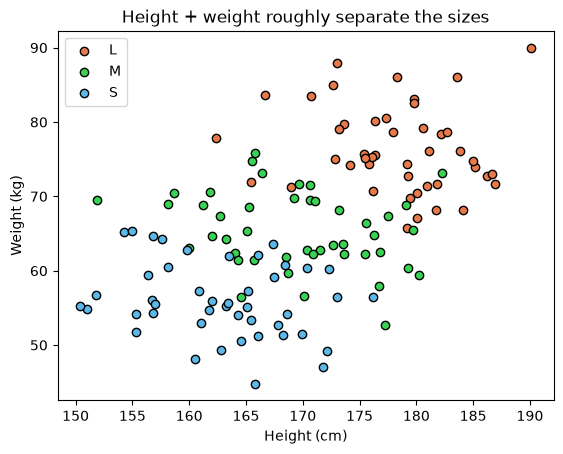

In [23]:
# import matplotlib.pyplot as plt
import matplotlib.pyplot as plt
# tip: loop over df.groupby('size') and scatter each group in a different colour
colors = {'S': '#5BB8E8', 'M': '#39D353', 'L': '#E8794B'}
for name, group in df.groupby('size'):
    plt.scatter(group.height_cm, group.weight_kg,
               color=colors[name], edgecolors='k', label=name, )

#      so the legend shows S, M, L
plt.xlabel("Height (cm)")
plt.ylabel("Weight (kg)")
plt.title("Height + weight roughly separate the sizes")
plt.legend()
plt.show()

## Step 3 — Features (X) and target (y)

`X` = the two measurement columns, `y` = the `size` column.

In [28]:
# X = df[['height_cm', 'weight_kg']]
X = df[['height_cm', 'weight_kg']]
# y = df['size']
y = df['size']
# print X.shape and the unique classes in y
print(f'Shape of Features: {X.shape}')
print(f'Unique classes: {list(y.unique())}')

Shape of Features: (135, 2)
Unique classes: ['S', 'L', 'M']


## Step 4 — Train / test split

Hold back 20% for testing (`random_state=42`).

In [35]:
# from sklearn.model_selection import train_test_split
from sklearn.model_selection import train_test_split
# X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
# print how many training and testing rows you have
print(f'Training rows: {X_train.shape[0]} \nTesting rows: {X_test.shape[0]}')

Training rows: 108 
Testing rows: 27


## Step 5 — Train the multiclass model

Use `LogisticRegression` (pass `max_iter=200` so it has room to converge).

In [39]:
# from sklearn.linear_model import LogisticRegression
from sklearn.linear_model import LogisticRegression
# create the model, fit it on X_train / y_train
model = LogisticRegression(max_iter=200)
model.fit(X_train, y_train)
# print model.classes_ to see the three sizes it learned
print(model.classes_)

['L' 'M' 'S']


## Step 6 — Predict on the test set

Compare predictions against the true sizes.

In [42]:
# y_pred = model.predict(X_test)
y_pred = model.predict(X_test)
# build a DataFrame with columns 'actual' and 'predicted' and show the first few rows
compare = pd.DataFrame({'actual':y_test.values, 'predicted':y_pred})
compare.head(10)

,actual,predicted
0,M,M
1,S,S
2,M,M
3,S,M
4,M,M
5,S,S
6,S,S
7,M,M
8,S,S
9,S,M


## Step 7 — Accuracy

In [43]:
# use model.score(X_test, y_test) and print the accuracy
model.score(X_test, y_test)

0.8888888888888888

## Step 8 — Confusion matrix

Build a 3×3 confusion matrix (use `labels=['S','M','L']` so it reads in order) and plot it.

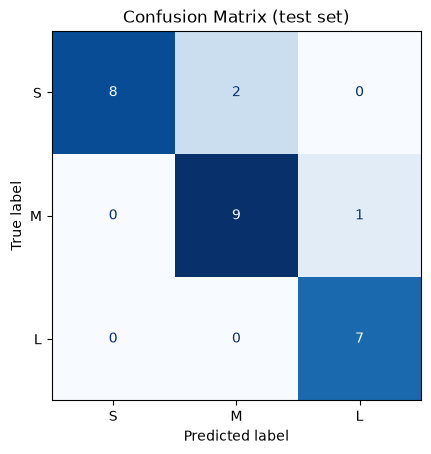

In [50]:
# from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
size_order = ['S', 'M', 'L']
# cm = confusion_matrix(y_test, y_pred, labels=size_order)
cm = confusion_matrix(y_test, y_pred, labels=size_order)
# print(cm)
# then ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=size_order).plot(...)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=size_order)
disp.plot(cmap='Blues',colorbar=False)
plt.title('Confusion Matrix (test set)')
plt.show()

**Question:** Where do the mistakes land — between neighbouring sizes (S↔M, M↔L), or does the model ever confuse an **S** with an **L**? Why do you think that is?

_Your answer here..._

## Step 9 — Classification report

Print precision / recall / f1 per size (again pass `labels=['S','M','L']`).

In [52]:
# from sklearn.metrics import classification_report
from sklearn.metrics import classification_report
# print(classification_report(y_test, y_pred, labels=['S', 'M', 'L']))
print(classification_report(y_test, y_pred, labels=['S', 'M', 'L']))

              precision    recall  f1-score   support

           S       1.00      0.80      0.89        10
           M       0.82      0.90      0.86        10
           L       0.88      1.00      0.93         7

    accuracy                           0.89        27
   macro avg       0.90      0.90      0.89        27
weighted avg       0.90      0.89      0.89        27



## Step 10 — Recommend a size for a new customer

A new shopper is **178 cm** and **74 kg**. Predict their size.

In [57]:
# build a one-row DataFrame with height_cm=178, weight_kg=74
customer = pd.DataFrame([{"height_cm":178, "weight_kg":74}])
# call model.predict(...) and print the recommended size
model.predict(customer)

array(['L'], dtype=object)

**Bonus challenge:** Try changing `random_state` in the split, or predicting for a customer right on a size boundary (e.g. 170 cm, 62 kg). Does the answer flip? 🤔